# Fine-tuning DistilBERT

Цель — применить готовый предобученный Transformer и сравнить его
с TF-IDF и Transformer, обученным с нуля.

Используется `distilbert-base-uncased` с новой классификационной
головой на 77 банковских интентов.

In [2]:
import json
import os
import time
from pathlib import Path

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

DATA_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 64
BATCH_SIZE = 16
EPOCHS = 3
PATIENCE = 1
LEARNING_RATE = 2e-5
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")

categories = sorted(train_df["category"].unique())
label_to_id = {label: index for index, label in enumerate(categories)}
id_to_label = {index: label for label, index in label_to_id.items()}

device = torch.device(
    "mps"
    if torch.backends.mps.is_available()
    else "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)

Device: cuda
Train: (7996, 2)
Validation: (2000, 2)


## Tokenizer и Dataset

Предобученный tokenizer сам выполняет subword-токенизацию,
добавляет специальные токены, padding и attention mask.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


class TransformerDataset(Dataset):
    def __init__(
        self,
        dataframe: pd.DataFrame,
        tokenizer,
        label_to_id: dict[str, int],
        max_length: int,
    ) -> None:
        self.encodings = tokenizer(
            dataframe["text"].tolist(),
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt",
        )
        self.labels = torch.tensor(
            [label_to_id[label] for label in dataframe["category"]], dtype=torch.long
        )

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> dict[str, torch.Tensor]:
        item = {key: values[index] for key, values in self.encodings.items()}
        item["labels"] = self.labels[index]
        return item


train_dataset = TransformerDataset(train_df, tokenizer, label_to_id, MAX_LENGTH)
val_dataset = TransformerDataset(val_df, tokenizer, label_to_id, MAX_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

batch = next(iter(train_loader))

print("input_ids:", tuple(batch["input_ids"].shape))
print("attention_mask:", tuple(batch["attention_mask"].shape))
print("labels:", tuple(batch["labels"].shape))

input_ids: (16, 64)
attention_mask: (16, 64)
labels: (16,)


## Модель и обучение

In [4]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(label_to_id), label2id=label_to_id, id2label=id_to_label
).to(device)

trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)

print("Обучаемых параметров:", f"{trainable_parameters:,}")

Обучаемых параметров: 67,012,685


In [5]:
def run_epoch(
    model, loader: DataLoader, optimizer: torch.optim.Optimizer | None = None
) -> dict:
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for batch in loader:
        batch = {key: value.to(device) for key, value in batch.items()}

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            output = model(**batch)
            loss = output.loss
            logits = output.logits

        if is_training:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        labels = batch["labels"]
        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(all_labels, all_predictions, average="macro"),
    }


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)

best_macro_f1 = -np.inf
best_state = None
epochs_without_improvement = 0
history = []

started_at = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, optimizer)
    val_metrics = run_epoch(model, val_loader)

    history.append(
        {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"],
        }
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val macro F1 {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_macro_f1 + 1e-4:
        best_macro_f1 = val_metrics["macro_f1"]
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping")
        break

training_seconds = time.perf_counter() - started_at

model.load_state_dict(best_state)
model.to(device)

history_df = pd.DataFrame(history)
display(history_df)

Epoch 01 | train loss 3.2931 | val loss 1.9863 | val macro F1 0.5935
Epoch 02 | train loss 1.3636 | val loss 0.7938 | val macro F1 0.8355
Epoch 03 | train loss 0.5591 | val loss 0.4584 | val macro F1 0.8818


,epoch,train_loss,val_loss,train_macro_f1,val_macro_f1
0,1,3.293117,1.986278,0.383030,0.593466
1,2,1.363559,0.793793,0.746344,0.835515
2,3,0.559062,0.458361,0.891629,0.881844


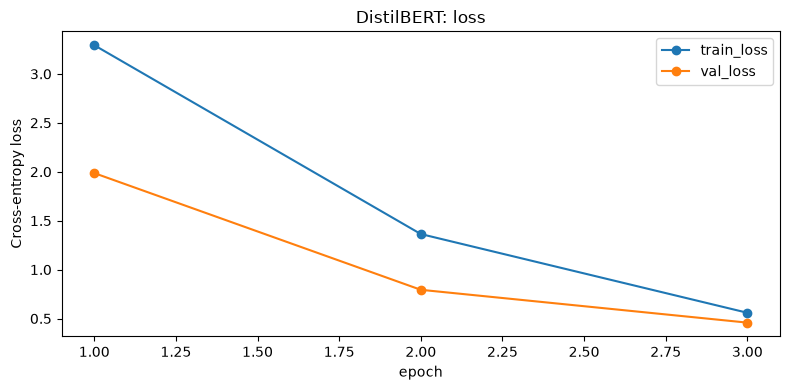

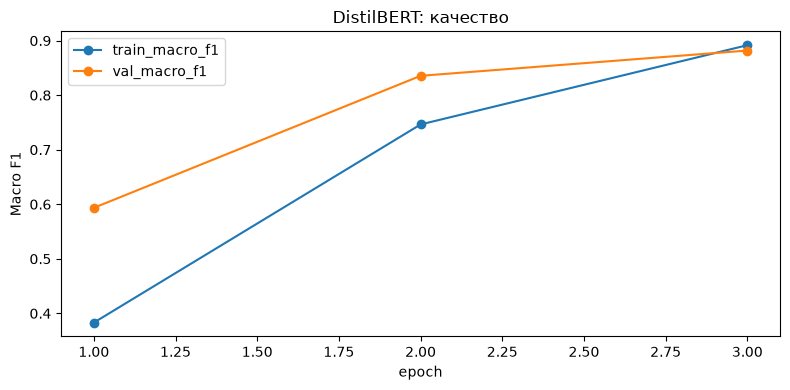

In [6]:
history_df.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", figsize=(8, 4))
plt.ylabel("Cross-entropy loss")
plt.title("DistilBERT: loss")
plt.tight_layout()
plt.show()

history_df.plot(
    x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o", figsize=(8, 4)
)
plt.ylabel("Macro F1")
plt.title("DistilBERT: качество")
plt.tight_layout()
plt.show()

## Validation и сохранение модели

In [7]:
@torch.no_grad()
def predict_loader(model, loader: DataLoader) -> tuple[list[int], list[float]]:
    model.eval()

    predictions = []
    confidence = []

    for batch in loader:
        inputs = {
            key: value.to(device) for key, value in batch.items() if key != "labels"
        }

        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=1)

        batch_confidence, batch_predictions = probabilities.max(dim=1)

        predictions.extend(batch_predictions.cpu().tolist())
        confidence.extend(batch_confidence.cpu().tolist())

    return predictions, confidence


val_prediction_ids, val_confidence = predict_loader(model, val_loader)

val_predictions = [id_to_label[prediction_id] for prediction_id in val_prediction_ids]

val_accuracy = accuracy_score(val_df["category"], val_predictions)
val_macro_f1 = f1_score(val_df["category"], val_predictions, average="macro")

print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation macro F1: {val_macro_f1:.4f}")

validation_predictions = val_df.assign(
    predicted_category=val_predictions, confidence=val_confidence
)

display(
    validation_predictions.query("category != predicted_category").sample(
        n=min(
            12,
            (
                validation_predictions["category"]
                != validation_predictions["predicted_category"]
            ).sum(),
        ),
        random_state=42,
    )[["text", "category", "predicted_category", "confidence"]]
)

Validation accuracy: 0.8915
Validation macro F1: 0.8818


,text,category,predicted_category,confidence
1945,How do I activate and link my new card?,card_linking,activate_my_card,0.914201
1977,I made a transfer recently but it has not chan...,pending_transfer,balance_not_updated_after_bank_transfer,0.842162
1279,I did all that was asked of me and I am rather...,Refund_not_showing_up,reverted_card_payment?,0.495114
1703,I cant transfer money into my account,beneficiary_not_allowed,transfer_into_account,0.317320
137,What proof do you need for my identification?,unable_to_verify_identity,verify_my_identity,0.462307
1086,What is my money worth in other countries?,exchange_rate,country_support,0.243343
1731,What was the issue with my topping up?,top_up_failed,top_up_reverted,0.370686
684,What happens if a merchant doesn't accept you...,reverted_card_payment?,declined_card_payment,0.374230
1946,How many payments can I make using a virtual c...,disposable_card_limits,getting_virtual_card,0.463538
1293,Is there a way for you to find out why my acco...,direct_debit_payment_not_recognised,reverted_card_payment?,0.526944


In [8]:
model_dir = MODELS_DIR / "distilbert_banking77"

model_dir.mkdir(parents=True, exist_ok=True)
(REPORTS_DIR / "predictions").mkdir(parents=True, exist_ok=True)

model.save_pretrained(model_dir)
tokenizer.save_pretrained(model_dir)

validation_predictions.to_csv(
    REPORTS_DIR / "predictions" / "distilbert_validation.csv", index=False
)
history_df.to_csv(REPORTS_DIR / "distilbert_history.csv", index=False)

summary = {
    "model": "distilbert",
    "validation_accuracy": val_accuracy,
    "validation_macro_f1": val_macro_f1,
    "training_seconds": training_seconds,
    "trainable_parameters": trainable_parameters,
    "pretrained_model": MODEL_NAME,
}

with open(REPORTS_DIR / "distilbert_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

## Вывод

После трёх эпох DistilBERT получил validation macro F1 **0,8818** против **0,8613** у TF-IDF. В этом сравнении предобученная модель оказалась полезнее Transformer с нуля. В следующем ноутбуке соберу результаты вместе и оценю выбранную модель на test.